achikin
akirillov
apichkur
ekashkarov
khabud
kovalexal
mfzaitseva
mkazachuk
mkhrebtov
ochikin
opichkur
pchikin
tchikina
tnikulina
vgorborukov


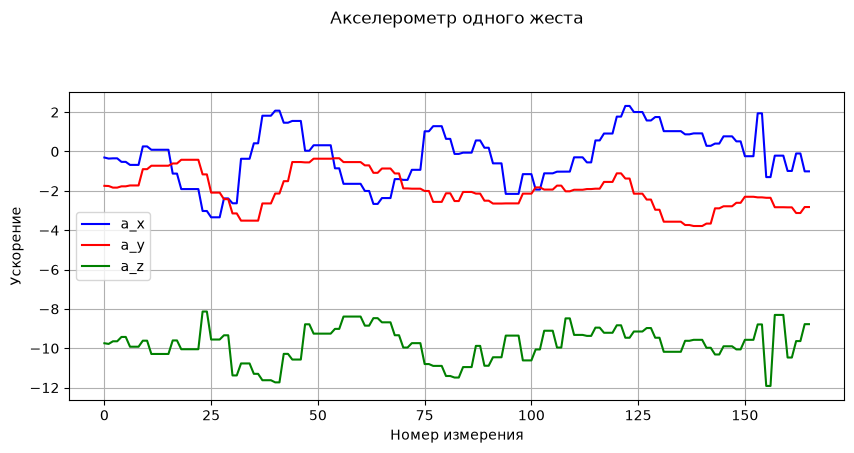

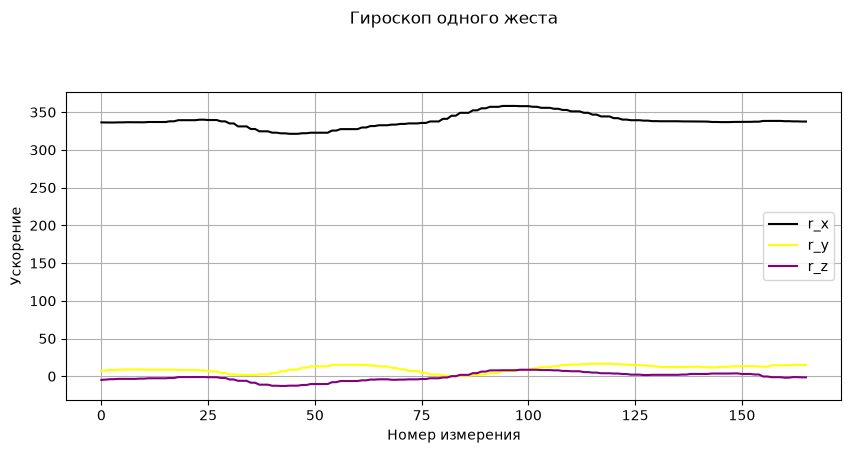

In [13]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, skew, sem
from scipy.signal import buttord, butter, sosfiltfilt
from scipy.ndimage import median_filter
import pandas as pd
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    auc,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.ensemble import IsolationForest
from IPython.display import display

dataset_root = Path(r"C:\Users\Даниил\IIT\task_1\data_legitimate")
user_folders = sorted([path for path in dataset_root.iterdir() if path.is_dir()])
for user in user_folders:
    print(user.name)

def get_gesture(user_folders, train_valid_test, num_user, num_file):

    result_path = user_folders[num_user] / "inf" / train_valid_test

    txt_files_len = len(list(result_path.glob("*.txt")))
    json_files_len = len(list(result_path.glob("*.json")))
    if txt_files_len: txt_or_json = "*.txt" 
    else: txt_or_json = "*.json"

    gesture_files = sorted(result_path.glob(txt_or_json))

    with open(gesture_files[num_file], "r", encoding = "utf-8") as file:
        file_data = json.load(file)

    if txt_or_json == "*.txt":
        measurements = file_data["params"]["data"]
        time_series_matrix_list = []
        
        for measurement in measurements:
            acceleration = measurement["acceleration"]
            rotation = measurement["rotation"]
            measurement_row = acceleration + rotation
            time_series_matrix_list.append(measurement_row)
    
    elif txt_or_json == "*.json":
        measurements = file_data
        
        time_series_matrix_list = []
        for measurement in measurements:
            if "x_rot" in measurement and "y_rot" in measurement and "z_rot" in measurement:
                measurement_row = [measurement["x_acc"], measurement["y_acc"],
                                measurement["z_acc"], measurement["x_rot"],
                                measurement["y_rot"], measurement["z_rot"]]
            elif "a_rot" in measurement and "b_rot" in measurement and "g_rot" in measurement:
                measurement_row = [measurement["x_acc"], measurement["y_acc"],
                                measurement["z_acc"], measurement["a_rot"],
                                measurement["b_rot"], measurement["g_rot"]]

            time_series_matrix_list.append(measurement_row)

    time_series_matrix = np.array(time_series_matrix_list, dtype=float)
    return time_series_matrix

time_series_matrix = get_gesture(user_folders, "train", num_user=5, num_file=0)
a_x = time_series_matrix[:, 0]
a_y = time_series_matrix[:, 1]
a_z = time_series_matrix[:, 2]

r_x = np.unwrap(time_series_matrix[:, 3], period=360, axis=0)
r_y = np.unwrap(time_series_matrix[:, 4], period=360, axis=0)
r_z = np.unwrap(time_series_matrix[:, 5], period=360, axis=0)

plt.figure(figsize=(10, 4))

plt.plot(a_x, label="a_x", color="blue")
plt.plot(a_y, label="a_y", color="red")
plt.plot(a_z, label="a_z", color="green")

plt.title("Акселерометр одного жеста\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()

plt.figure(figsize=(10, 4))

plt.plot(r_x, label="r_x", color="black")
plt.plot(r_y, label="r_y", color="yellow")
plt.plot(r_z, label="r_z", color="purple")

plt.title("Гироскоп одного жеста\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()

# Фильтр Баттерворта и график для атрибута a_x

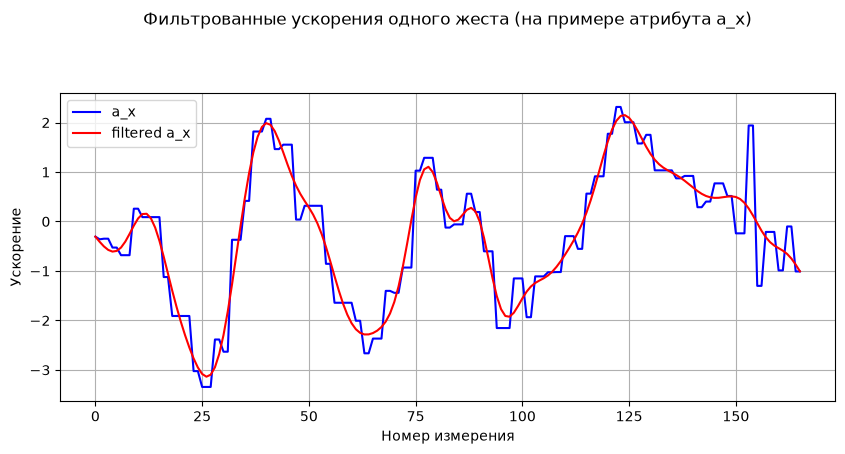

In [14]:
def butterworth_filter_gesture(time_series_matrix):
    wp = 0.17
    ws = 0.30
    gpass = 1
    gstop = 30

    order, cutoff = buttord(wp, ws, gpass, gstop)
    sos = butter(order, cutoff, btype="low", output="sos")
    filtered_matrix = sosfiltfilt(sos, time_series_matrix, axis=0)

    return filtered_matrix


filtered_time_series_matrix_bu = butterworth_filter_gesture(time_series_matrix)
plt.figure(figsize=(10, 4))

plt.plot(time_series_matrix[:, 0], label="a_x", color="blue")
plt.plot(filtered_time_series_matrix_bu[:, 0], label="filtered a_x", color="red")

plt.title("Фильтрованные ускорения одного жеста (на примере атрибута a_x)\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()

# Медианнй фильтр и график для атрибута a_x

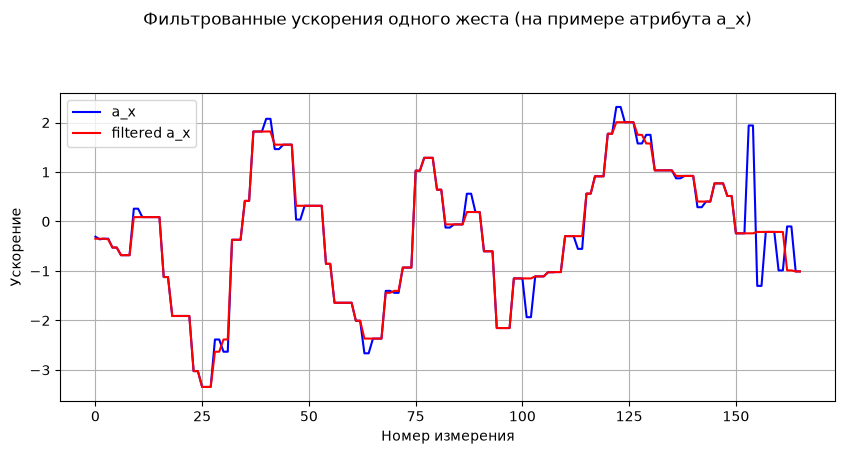

In [15]:
def median_filter_gesture(time_series_matrix, window_size=5):
    return median_filter(
        time_series_matrix,
        size=(window_size, 1)
    )


filtered_time_series_matrix_me = median_filter_gesture(time_series_matrix)

plt.figure(figsize=(10, 4))

plt.plot(time_series_matrix[:, 0], label="a_x", color="blue")
plt.plot(filtered_time_series_matrix_me[:, 0], label="filtered a_x", color="red")

plt.title("Фильтрованные ускорения одного жеста (на примере атрибута a_x)\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()


# Приведение типов данных

### Первый тип (на примере ekashkarov)  
"index": 11,  
"x_acc": 0.054819969946146005,  
"y_acc": -0.12193126618862152,  
"z_acc": 0.10602058035135269,  
"x_rot": 10.774065047730467,  
"y_rot": -7.272262918758071,  
"z_rot": 0.27350900225848973

### Второй тип (на примере akirillov)  
"index" : 0,  
"x_acc" : 0.017166823148727417,  
"x_rot" : 0.18656189739704132,  
"y_acc" : 0.011419892311096191,  
"y_rot" : -0.23820747435092926,  
"z_acc" : -0.014128893613815308,  
"z_rot" : 0.052343972027301788

### Третий тип (на примере kovalexal)  
"acceleration": [  
-0.46148237912827167,  
-1.997512368022534,  
-9.799467321954294  
],  
"rotation": [  
0.5139335850022401,  
11.473997809167553,  
-3.046416849535602  
],  
"time": 1423916807475

### Вывод:  
| Тип | Ускорение | Вращение | Гравитация |
|---|---|---|---|
| 1 — ekashkarov | м/с² | градусы/с | вероятно удалена |
| 2 — akirillov | g | радианы/с | вероятно удалена |
| 3 — kovalexal | м/с² | углы ориентации в градусах | присутствует |

In [16]:
def prepare_rot_acc(time_series_matrix, num_user):

    # ekashkarov, ochikin
    if num_user in {3, 9}:
        time_series_matrix[:, 0:3] /= 9.8
        time_series_matrix[:, 3:6] *= np.pi / 180

    # kovalexal, mfzaitseva, mkazachuk
    if num_user in {5, 6, 7}:
        time_series_matrix[:, 0:3] /= 9.8
        
        time_series_matrix[:, 3:6] = np.unwrap(
            time_series_matrix[:, 3:6],
            period=360,
            axis=0
        )
        
        time_series_matrix[:, 3:6] = np.deg2rad(time_series_matrix[:, 3:6])
        
        time_seconds = 0.02
        time_series_matrix[:, 3:6] = np.gradient(
            time_series_matrix[:, 3:6],
            time_seconds,
            axis=0
        )
    return time_series_matrix

# Построим графики всех временных рядов одного пользователя

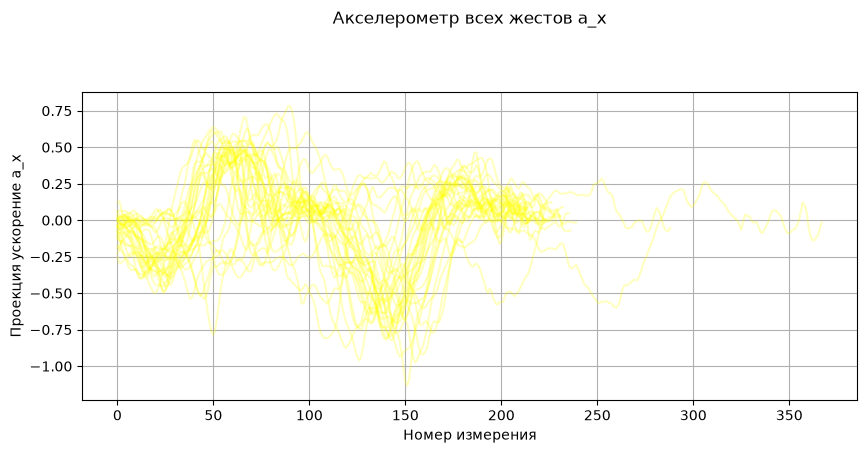

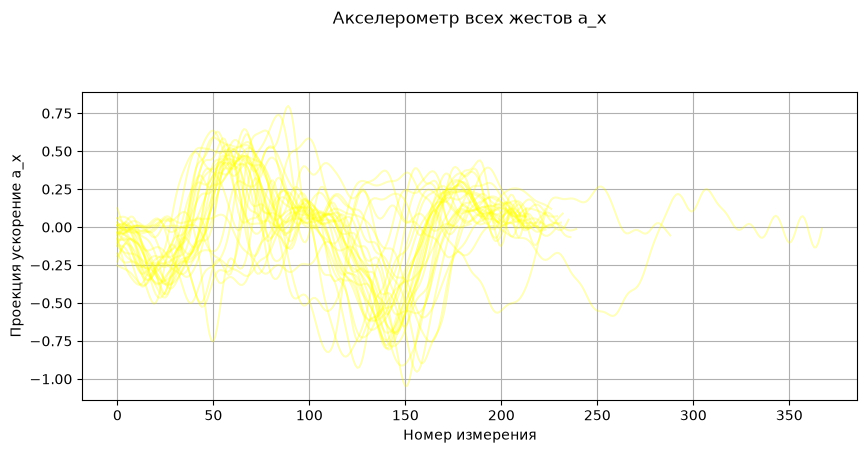

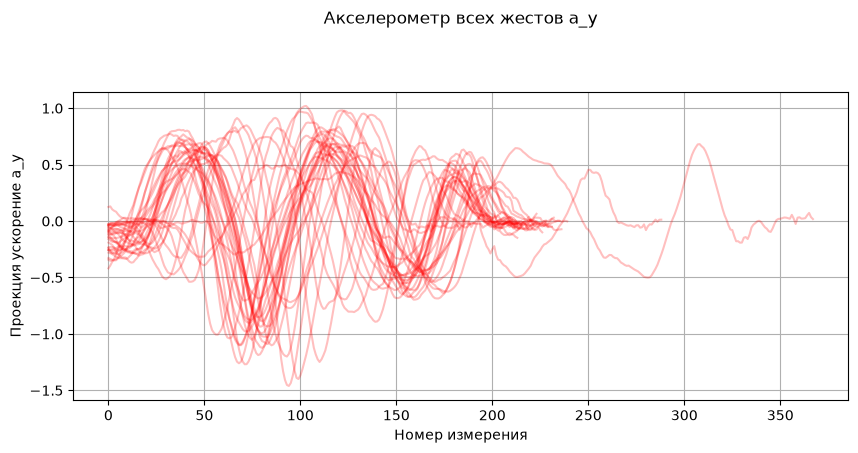

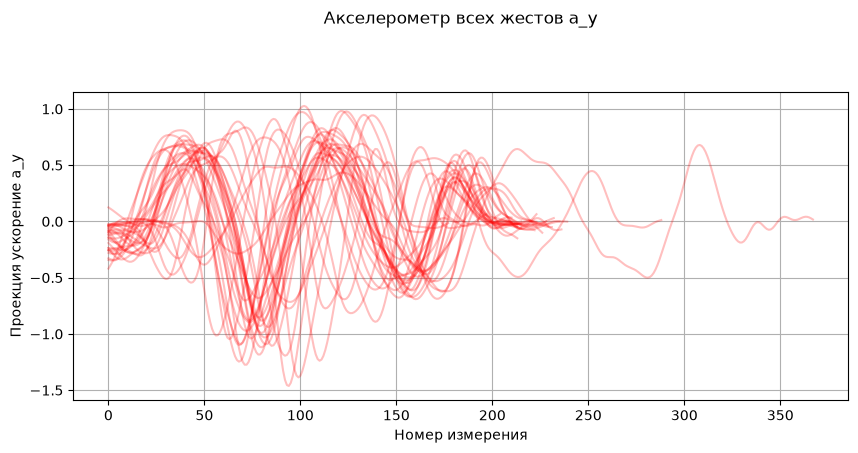

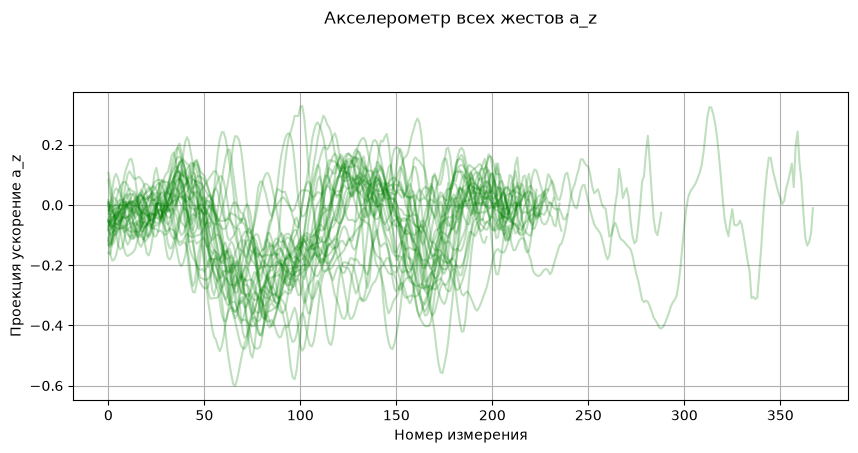

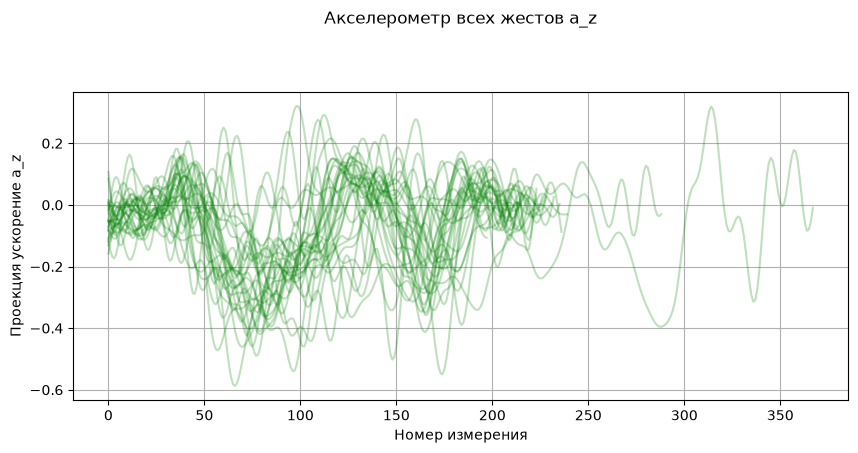

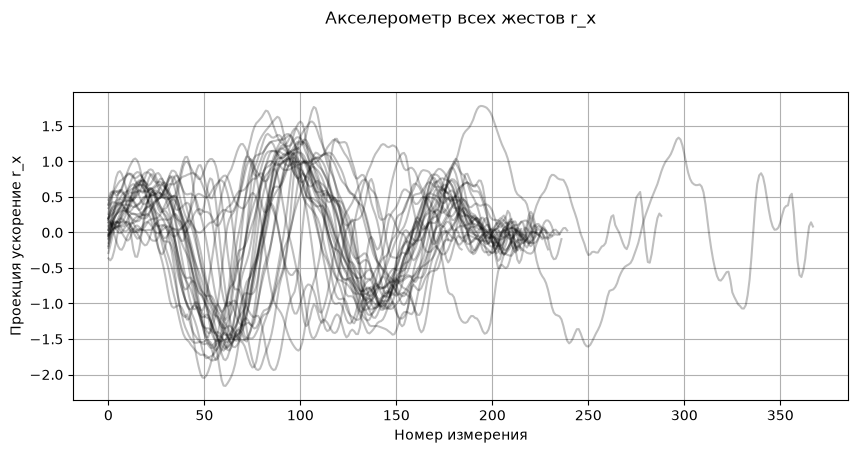

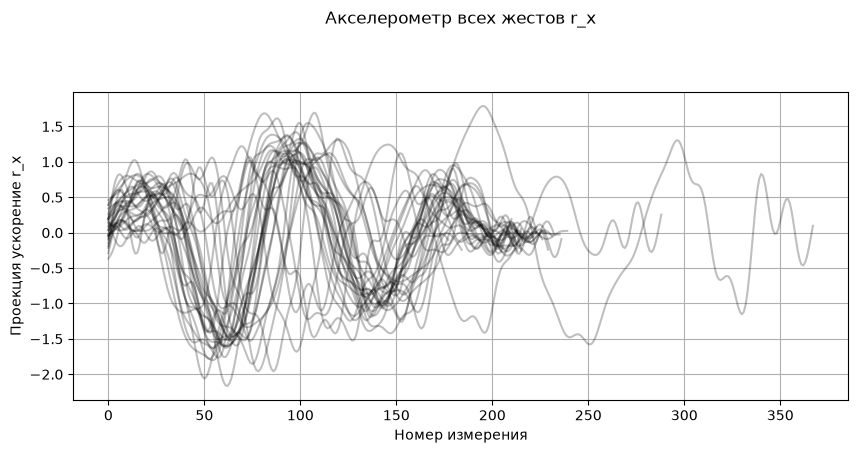

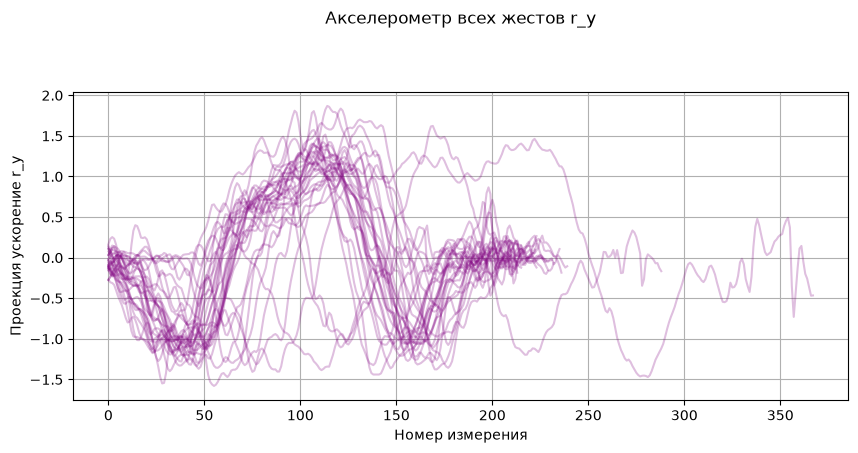

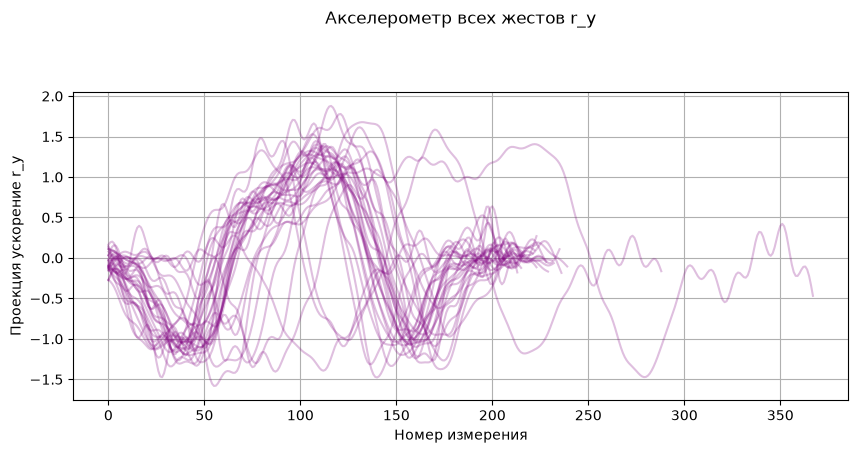

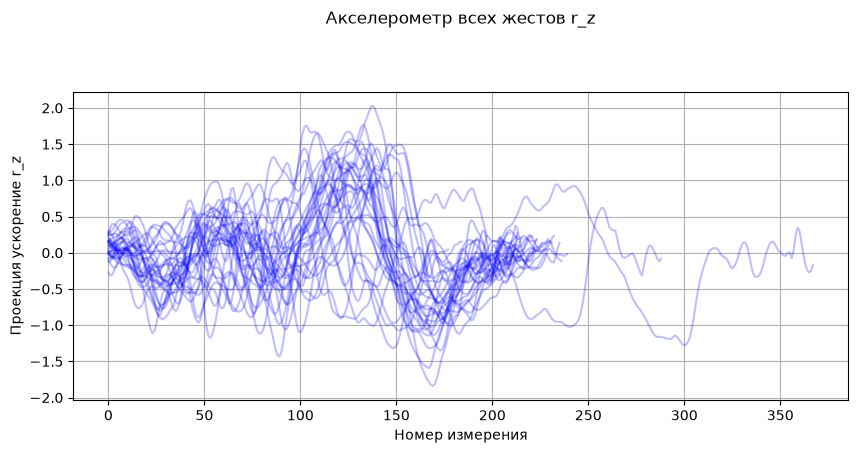

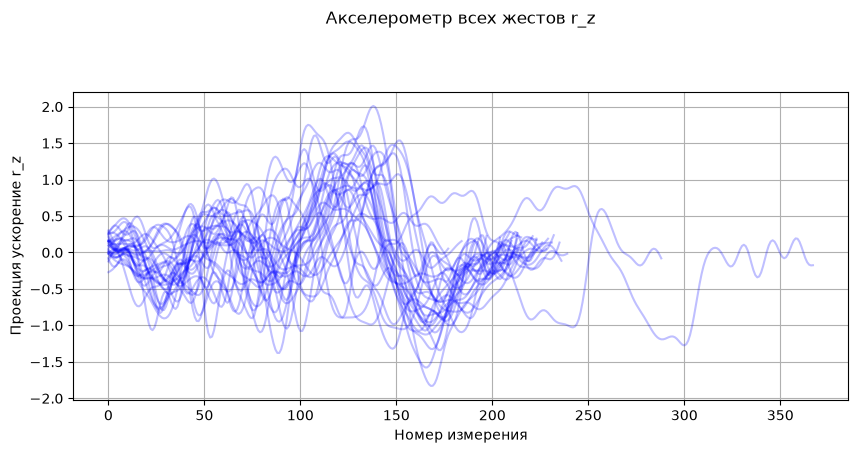

In [17]:
def full_filt_gesture(user_folders, train_valid_test, 
                      num_user, num_file, filt):

    time_series_matrix = get_gesture(user_folders, train_valid_test, num_user, num_file)
    time_series_matrix = prepare_rot_acc(time_series_matrix, num_user)

    if filt == 1: time_series_matrix = butterworth_filter_gesture(time_series_matrix)
    if filt == 2: time_series_matrix = median_filter_gesture(time_series_matrix)
    if filt == 3:
        time_series_matrix = median_filter_gesture(time_series_matrix)
        time_series_matrix = butterworth_filter_gesture(time_series_matrix)
    
    return time_series_matrix
    
def build_one_attribute_plot(user_folders, train_valid_test, num_user, 
                             num_time_series, filt):
    plt.figure(figsize=(10, 4))
    match num_time_series:
        case 0:
            attribute_name = "a_x"
            color_name = "yellow"
        case 1:
            attribute_name = "a_y"
            color_name = "red"
        case 2:
            attribute_name = "a_z"
            color_name = "green"
        case 3:
            attribute_name = "r_x"
            color_name = "black"
        case 4:
            attribute_name = "r_y"
            color_name = "purple"
        case 5:
            attribute_name = "r_z"
            color_name = "blue"

    result_path = user_folders[num_user] / "inf" / train_valid_test
    gesture_len = len(list(result_path.iterdir())) - 1
    
    for i in range(gesture_len):
        time_series_matrix = full_filt_gesture(user_folders, train_valid_test, num_user, i, filt)
        plt.plot(time_series_matrix[:, num_time_series], label=attribute_name, color=color_name, alpha=0.25)

    plt.title("Акселерометр всех жестов " + attribute_name + "\n\n\n")
    plt.xlabel("Номер измерения")
    plt.ylabel("Проекция ускорение " + attribute_name)
    plt.grid(True)
    
    plt.show()

amount_all_attributes = 6
for i in range(amount_all_attributes):
    build_one_attribute_plot(user_folders, train_valid_test="train", 
                             num_user=0, num_time_series=i, filt=0)
    build_one_attribute_plot(user_folders, train_valid_test="train", 
                             num_user=0, num_time_series=i, filt=1)

# Создаем таблицу для обучения модели: жесты x 72 признака

In [18]:
def extract_features(processed_gesture):
    mean_values = np.mean(processed_gesture, axis=0)
    std_values = np.std(processed_gesture,axis=0)
    min_values = np.min(processed_gesture,axis=0)
    max_values = np.max(processed_gesture,axis=0)
    median_values = np.median(processed_gesture,axis=0)
    q1_values = np.percentile(processed_gesture, 25,axis=0)
    q3_values = np.percentile(processed_gesture, 75,axis=0)
    excess_values = kurtosis(processed_gesture, axis=0, bias=False)
    skewness_values = skew(processed_gesture, axis=0, bias=False)
    p87_values = np.percentile(processed_gesture, 87, axis=0)
    iqr_values = q3_values - q1_values
    sem_values = sem(processed_gesture, axis=0)
    
    features = np.concatenate([
        mean_values,
        std_values,
        min_values,
        max_values,
        median_values,
        q1_values,
        q3_values,
        excess_values,
        skewness_values,
        p87_values,
        iqr_values,
        sem_values
    ])

    return features


def get_user_features(user_folders, train_valid_test, num_user, filt):
    result_path = user_folders[num_user] / "inf" / train_valid_test
    
    if len(list(result_path.glob("*.txt"))) > 0: 
        gesture_files = list(result_path.glob("*.txt"))
    else: 
        gesture_files = list(result_path.glob("*.json"))

    feature_rows = []
    for i in range(len(gesture_files)):
        filtered_gesture = full_filt_gesture(
            user_folders,
            train_valid_test,
            num_user=num_user,
            num_file=i,
            filt=filt
        )

        features = extract_features(filtered_gesture)
        feature_rows.append(features)
    return np.array(feature_rows, dtype=float)

attribute_names = ["a_x", "a_y", "a_z", "r_x", "r_y", "r_z"]
statistic_names = ["mean", "std", "min", "max", "median", "q1", "q3", "excess", "skewness", "p87", "iqr", "sem"]
feature_names = []

for statistic_name in statistic_names:
    for attribute_name in attribute_names:
        feature_name = (statistic_name + "_" + attribute_name)
        feature_names.append(feature_name)

feature_rows = []
feature_rows = get_user_features(user_folders, "train", num_user=0, filt=1)
X_train = feature_rows

gesture_file_names = []
result_path = user_folders[0] / "inf" / "train"
    
if len(list(result_path.glob("*.txt"))) > 0: 
    gesture_files = list(result_path.glob("*.txt"))
else: 
    gesture_files = list(result_path.glob("*.json"))

for i in range(len(gesture_files)):
    gesture_file_names.append(gesture_files[i].name)

features_table = pd.DataFrame(feature_rows, index=gesture_file_names, columns=feature_names)
features_table.index.name = "gesture_file"

pd.set_option("display.max_columns", None)
display(features_table.head())

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
gesture_file,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
s_infinity_11_12_2022_0_17_19.json,-0.053477,0.026188,-0.076375,0.030012,0.013004,0.010478,0.212254,0.321915,0.146778,0.852330,0.802156,0.476886,-0.585463,-0.620304,-0.395637,-1.578372,-1.472751,-1.274473,0.359413,0.679530,0.318767,1.789530,1.405902,0.910753,-0.035000,-0.005829,-0.045658,0.142445,-0.021489,0.058521,-0.181787,-0.186972,-0.182904,-0.653433,-0.507015,-0.243535,0.063512,0.293952,0.033013,0.643442,0.524933,0.350672,-0.019536,-0.670093,-0.404576,-0.836590,-0.841933,0.577305,-0.378085,0.053901,-0.238719,-0.117591,0.062412,-0.642775,0.201444,0.422945,0.063650,0.995541,1.161593,0.497218,0.245299,0.480924,0.215917,1.296875,1.031948,0.594207,0.011080,0.016804,0.007662,0.044491,0.041872,0.024893
s_infinity_11_12_2022_0_17_38.json,-0.019213,0.019203,-0.051377,-0.029481,-0.011499,0.003877,0.229878,0.344651,0.121864,0.680648,0.777724,0.464242,-0.564343,-0.815402,-0.364178,-1.478604,-1.405456,-1.026890,0.421629,0.562088,0.139642,1.243586,1.585805,0.845642,0.005004,-0.010627,-0.024570,0.034408,-0.063968,0.044612,-0.175314,-0.205793,-0.150317,-0.312900,-0.544671,-0.292670,0.161074,0.338032,0.043183,0.366025,0.594886,0.320512,-0.238982,-0.482214,-0.564457,-0.359247,-0.741244,-0.308865,-0.365987,-0.300001,-0.541365,-0.383341,0.188023,-0.333850,0.225041,0.468147,0.072239,0.766860,1.047399,0.546921,0.336388,0.543825,0.193499,0.678925,1.139557,0.613182,0.013546,0.020309,0.007181,0.040108,0.045828,0.027356
s_infinity_11_12_2022_0_19_18.json,-0.023291,0.021345,-0.050465,-0.027076,-0.047118,-0.012399,0.285817,0.480477,0.144780,0.671749,0.693963,0.607664,-0.552503,-1.046405,-0.366320,-1.415651,-0.989576,-0.988329,0.585062,0.815931,0.321082,1.064495,1.479997,1.150964,0.014448,-0.040146,-0.043857,0.116555,-0.164784,-0.011538,-0.254705,-0.271919,-0.164630,-0.412124,-0.664285,-0.540445,0.182003,0.435135,0.038589,0.538294,0.267329,0.417505,-0.632223,-0.715144,0.031560,-0.814587,-0.380533,-1.003991,-0.103573,-0.173019,0.171721,-0.525533,0.764012,0.193550,0.252881,0.645903,0.074970,0.713774,0.910191,0.820870,0.436709,0.707054,0.203218,0.950419,0.931614,0.957950,0.021483,0.036115,0.010882,0.050492,0.052161,0.045675
s_infinity_11_12_2022_0_19_26.json,-0.021070,0.033198,-0.055340,-0.038744,-0.036439,-0.006328,0.327208,0.486934,0.142683,0.665219,0.693526,0.600765,-0.823441,-1.013781,-0.322439,-1.131695,-1.090035,-0.894545,0.493704,0.911024,0.236750,1.220965,1.330286,1.314110,0.019899,0.005063,-0.046458,-0.006667,-0.107086,-0.063768,-0.241542,-0.302589,-0.190918,-0.584541,-0.639408,-0.467827,0.256612,0.456798,0.055620,0.506433,0.444701,0.283084,-0.301583,-0.715556,-1.029891,-1.020419,-0.881997,-0.457646,-0.633329,-0.235292,0.088590,-0.135659,0.332395,0.534686,0.334469,0.617374,0.104870,0.720308,1.004108,0.924484,0.498154,0.759387,0.246538,1.090973,1.084109,0.750911,0.024122,0.035897,0.010519,0.049041,0.051127,0.044289
s_infinity_11_12_2022_0_20_36.json,-0.039779,0.037564,-0.095024,-0.014994,0.000739,0.011968,0.370001,0.570263,0.166778,0.843010,0.907970,0.605214,-1.046485,-1.462321,-0.539488,-1.957033,-1.343348,-0.957605,0.739486,0.977705,0.168822,1.547696,1.778205,1.382587,-0.004710,-0.008155,-0.057709,0.077371,-0.087160,0.017195,-0.253547,-0.358450,-0.195917,-0.603010,-0.661621,-0.501552,0.137979,0.516230,0.034051,0.635255,0.558280,0.35600

# Cтроим матрицу корреляций

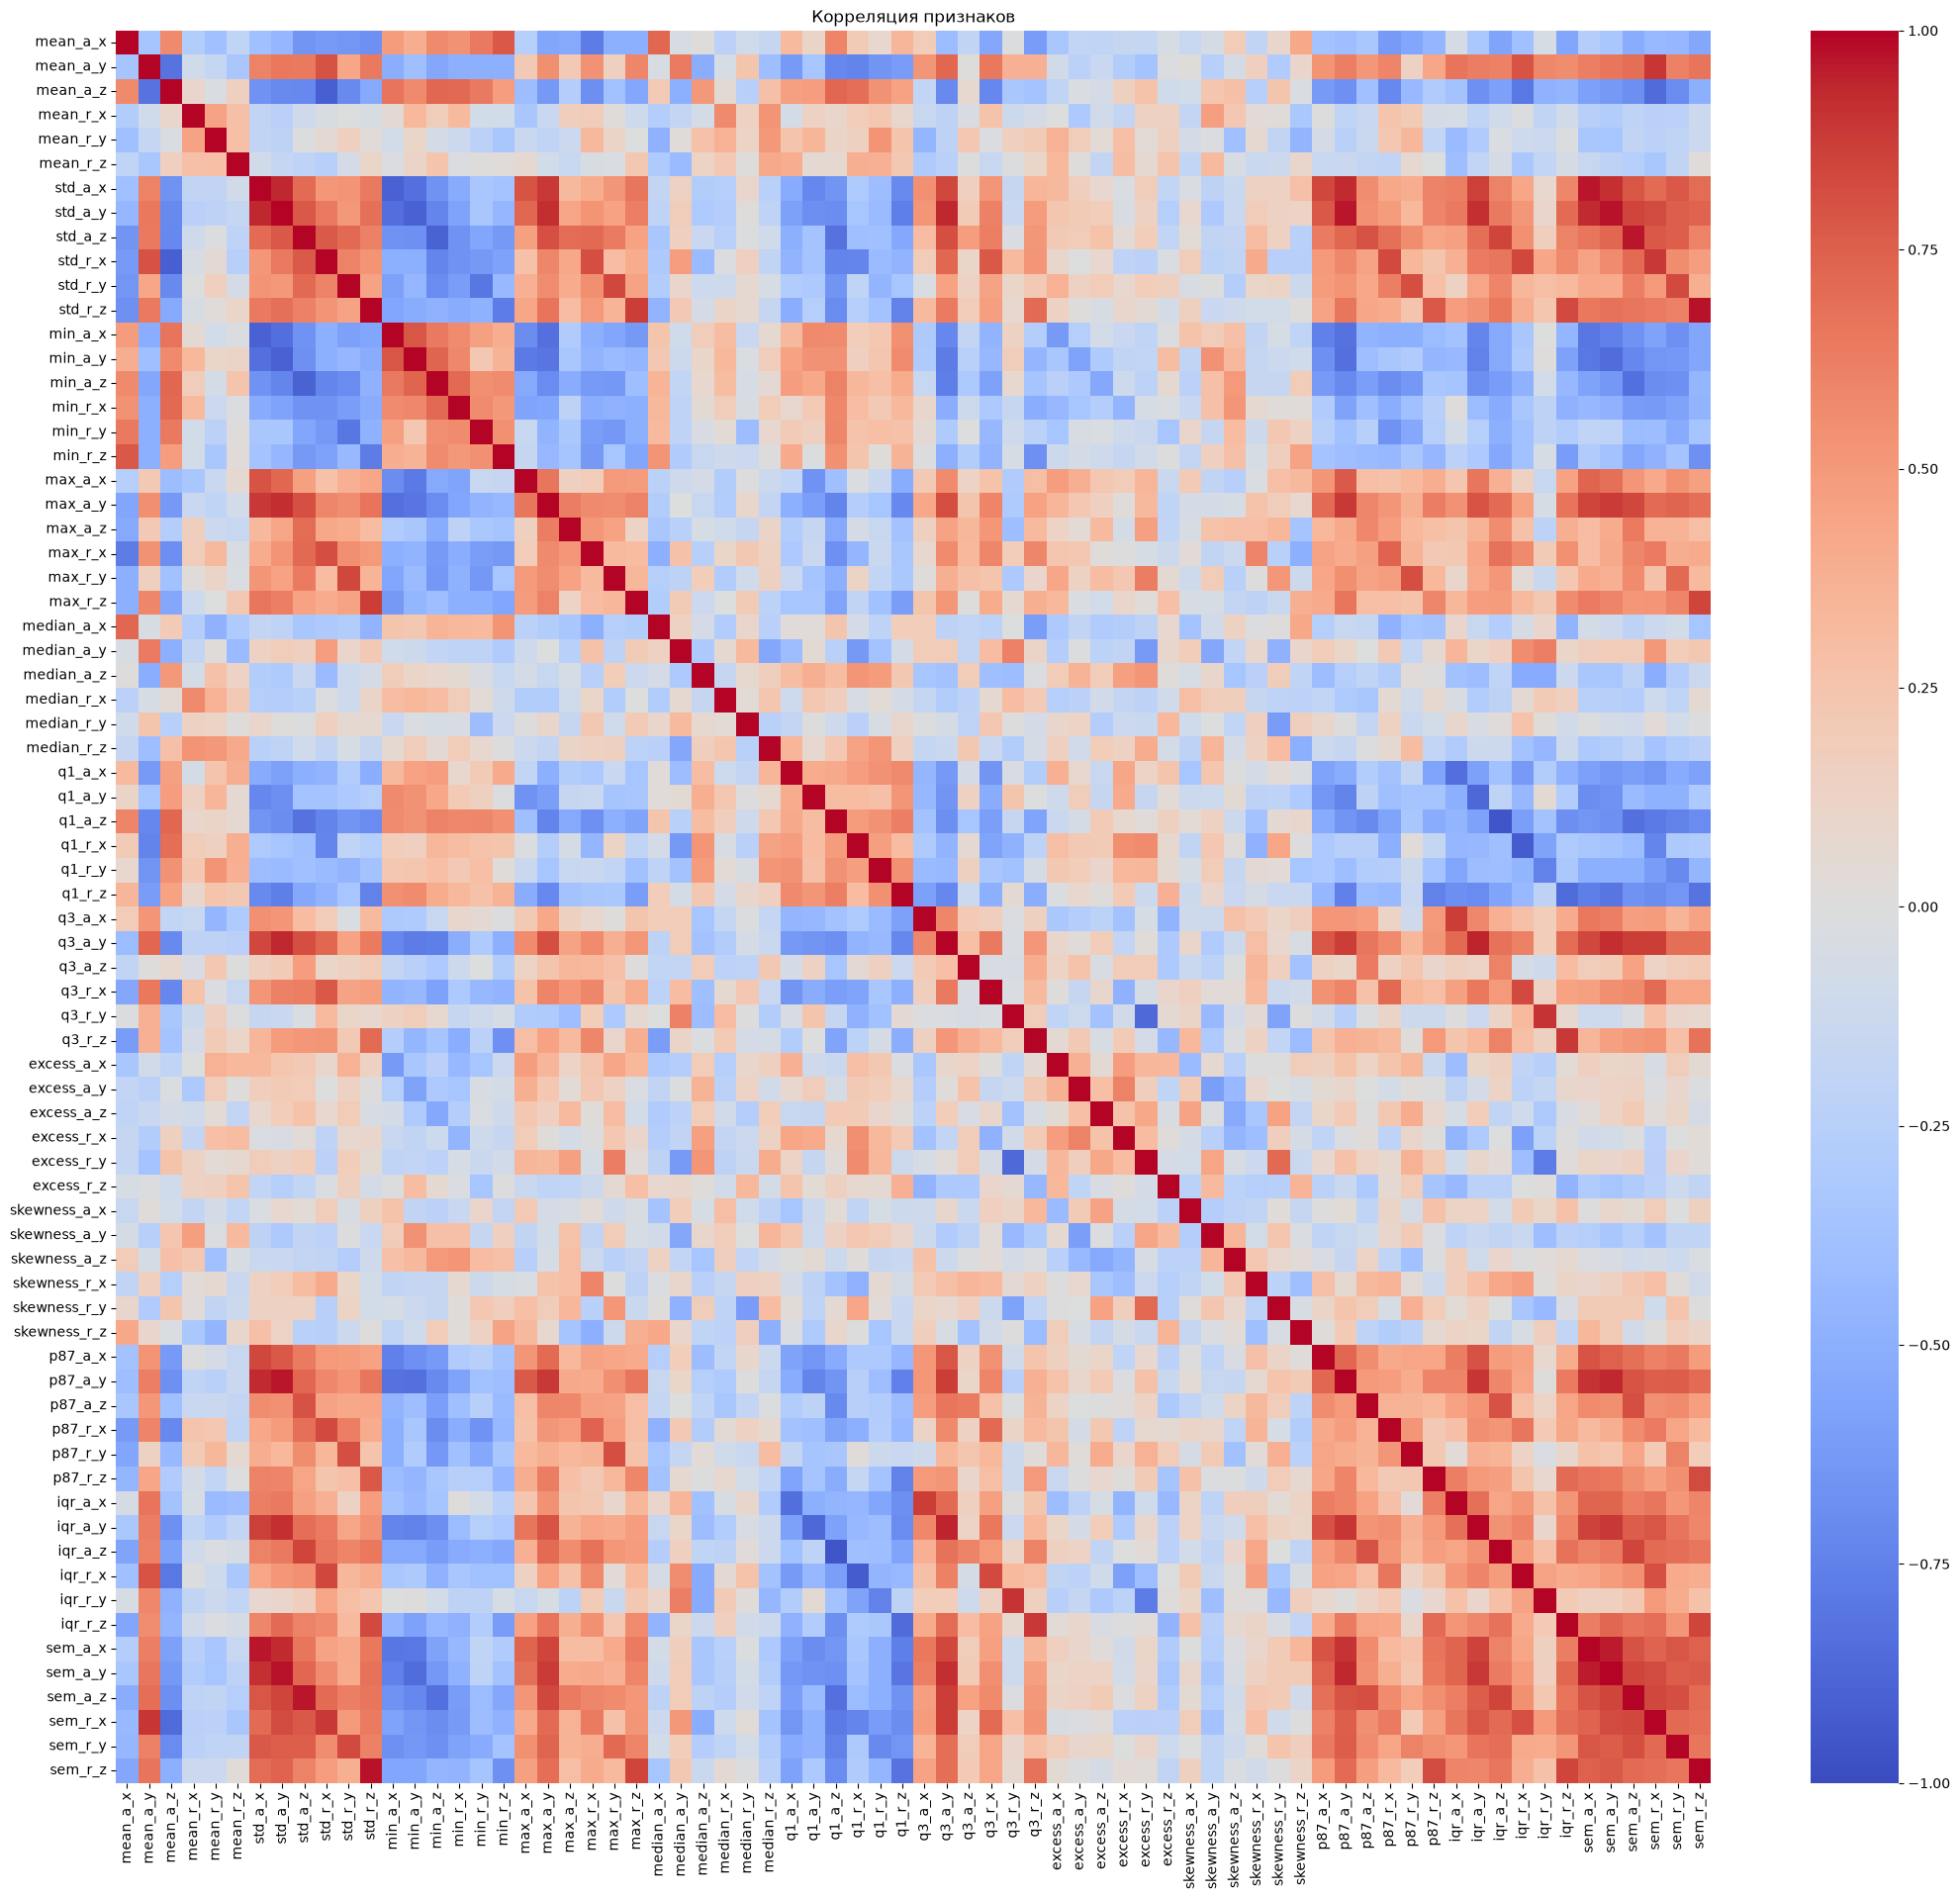

std_a_y   sem_a_y    0.975428
std_r_z   sem_r_z    0.974982
std_a_x   sem_a_x    0.967519
std_a_y   p87_a_y    0.963703
std_a_z   sem_a_z    0.961141
q1_a_z    iqr_a_z   -0.957138
sem_a_x   sem_a_y    0.956747
q3_a_y    iqr_a_y    0.942545
std_a_x   std_a_y    0.934636
p87_a_y   sem_a_y    0.934165
std_a_y   q3_a_y     0.930966
std_a_x   p87_a_y    0.928495
q1_r_x    iqr_r_x   -0.926410
std_a_y   sem_a_x    0.923201
          max_a_y    0.916899
q3_a_y    sem_a_y    0.914321
std_a_x   sem_a_y    0.913928
std_a_y   iqr_a_y    0.908542
mean_a_z  std_r_x   -0.907404
p87_a_y   sem_a_x    0.904719
dtype: float64

In [19]:
correlation = features_table.corr()

plt.figure(figsize=(26, 23))

sns.heatmap(correlation, cmap="coolwarm", center=0, vmin=-1, vmax=1)

plt.title("Корреляция признаков")
plt.show()

upper_triangle = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))

strong_pairs = upper_triangle.stack()
strong_pairs = strong_pairs[strong_pairs.abs() > 0.9]

display(strong_pairs.sort_values(key=abs, ascending=False))

 # Стандартизация

In [20]:
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)

scaled_features_table = pd.DataFrame(
    X_train_scaled,
    index=features_table.index,
    columns=features_table.columns
)
print('\n\n', "                                              Б Ы Л О")
display(features_table.head())
print('\n\n',"                                              С Т А Л О")
display(scaled_features_table.head())


def find_universal_cor_features(user_folders, filt, feature_names, threshold):
    pair_counts = {}

    for user_index in range(len(user_folders)):

        X_train = get_user_features(user_folders, "train", num_user=user_index, filt=filt)

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        
        correlation = np.corrcoef(X_train_scaled, rowvar=False)

        for first_index in range(len(feature_names)):
            for second_index in range(first_index + 1, len(feature_names)):
                correlation_value = correlation[first_index, second_index]

                if abs(correlation_value) > threshold:
                    pair = (first_index, second_index)

                    if pair not in pair_counts:
                        pair_counts[pair] = 0

                    pair_counts[pair] += 1

    indices_to_drop = set()
    minimum_users = len(user_folders) - 1

    for pair in pair_counts:
        users_count = pair_counts[pair]

        if users_count >= minimum_users:
            first_index = pair[0]
            second_index = pair[1]
            
            if first_index not in indices_to_drop:
                indices_to_drop.add(second_index)

    selected_indices = []
    for index in range(len(feature_names)):
        if index not in indices_to_drop:
            selected_indices.append(index)

    features_to_drop = set()
    for index in indices_to_drop:
        features_to_drop.add(feature_names[index])

    return selected_indices, features_to_drop


selected_indices, features_to_drop = find_universal_cor_features(user_folders, 1, feature_names, 0.9)
print("Признаки, которые мы выбросим отовсюду:")
display(*features_to_drop)



                                               Б Ы Л О


,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
gesture_file,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
s_infinity_11_12_2022_0_17_19.json,-0.053477,0.026188,-0.076375,0.030012,0.013004,0.010478,0.212254,0.321915,0.146778,0.852330,0.802156,0.476886,-0.585463,-0.620304,-0.395637,-1.578372,-1.472751,-1.274473,0.359413,0.679530,0.318767,1.789530,1.405902,0.910753,-0.035000,-0.005829,-0.045658,0.142445,-0.021489,0.058521,-0.181787,-0.186972,-0.182904,-0.653433,-0.507015,-0.243535,0.063512,0.293952,0.033013,0.643442,0.524933,0.350672,-0.019536,-0.670093,-0.404576,-0.836590,-0.841933,0.577305,-0.378085,0.053901,-0.238719,-0.117591,0.062412,-0.642775,0.201444,0.422945,0.063650,0.995541,1.161593,0.497218,0.245299,0.480924,0.215917,1.296875,1.031948,0.594207,0.011080,0.016804,0.007662,0.044491,0.041872,0.024893
s_infinity_11_12_2022_0_17_38.json,-0.019213,0.019203,-0.051377,-0.029481,-0.011499,0.003877,0.229878,0.344651,0.121864,0.680648,0.777724,0.464242,-0.564343,-0.815402,-0.364178,-1.478604,-1.405456,-1.026890,0.421629,0.562088,0.139642,1.243586,1.585805,0.845642,0.005004,-0.010627,-0.024570,0.034408,-0.063968,0.044612,-0.175314,-0.205793,-0.150317,-0.312900,-0.544671,-0.292670,0.161074,0.338032,0.043183,0.366025,0.594886,0.320512,-0.238982,-0.482214,-0.564457,-0.359247,-0.741244,-0.308865,-0.365987,-0.300001,-0.541365,-0.383341,0.188023,-0.333850,0.225041,0.468147,0.072239,0.766860,1.047399,0.546921,0.336388,0.543825,0.193499,0.678925,1.139557,0.613182,0.013546,0.020309,0.007181,0.040108,0.045828,0.027356
s_infinity_11_12_2022_0_19_18.json,-0.023291,0.021345,-0.050465,-0.027076,-0.047118,-0.012399,0.285817,0.480477,0.144780,0.671749,0.693963,0.607664,-0.552503,-1.046405,-0.366320,-1.415651,-0.989576,-0.988329,0.585062,0.815931,0.321082,1.064495,1.479997,1.150964,0.014448,-0.040146,-0.043857,0.116555,-0.164784,-0.011538,-0.254705,-0.271919,-0.164630,-0.412124,-0.664285,-0.540445,0.182003,0.435135,0.038589,0.538294,0.267329,0.417505,-0.632223,-0.715144,0.031560,-0.814587,-0.380533,-1.003991,-0.103573,-0.173019,0.171721,-0.525533,0.764012,0.193550,0.252881,0.645903,0.074970,0.713774,0.910191,0.820870,0.436709,0.707054,0.203218,0.950419,0.931614,0.957950,0.021483,0.036115,0.010882,0.050492,0.052161,0.045675
s_infinity_11_12_2022_0_19_26.json,-0.021070,0.033198,-0.055340,-0.038744,-0.036439,-0.006328,0.327208,0.486934,0.142683,0.665219,0.693526,0.600765,-0.823441,-1.013781,-0.322439,-1.131695,-1.090035,-0.894545,0.493704,0.911024,0.236750,1.220965,1.330286,1.314110,0.019899,0.005063,-0.046458,-0.006667,-0.107086,-0.063768,-0.241542,-0.302589,-0.190918,-0.584541,-0.639408,-0.467827,0.256612,0.456798,0.055620,0.506433,0.444701,0.283084,-0.301583,-0.715556,-1.029891,-1.020419,-0.881997,-0.457646,-0.633329,-0.235292,0.088590,-0.135659,0.332395,0.534686,0.334469,0.617374,0.104870,0.720308,1.004108,0.924484,0.498154,0.759387,0.246538,1.090973,1.084109,0.750911,0.024122,0.035897,0.010519,0.049041,0.051127,0.044289
s_infinity_11_12_2022_0_20_36.json,-0.039779,0.037564,-0.095024,-0.014994,0.000739,0.011968,0.370001,0.570263,0.166778,0.843010,0.907970,0.605214,-1.046485,-1.462321,-0.539488,-1.957033,-1.343348,-0.957605,0.739486,0.977705,0.168822,1.547696,1.778205,1.382587,-0.004710,-0.008155,-0.057709,0.077371,-0.087160,0.017195,-0.253547,-0.358450,-0.195917,-0.603010,-0.661621,-0.501552,0.137979,0.516230,0.034051,0.635255,0.558280,0.35600



                                               С Т А Л О


,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
gesture_file,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
s_infinity_11_12_2022_0_17_19.json,-2.596414,-0.682163,-0.366423,2.917637,2.282368,0.541414,-2.023615,-1.687069,0.342257,1.302376,0.848990,-0.795711,1.152715,1.903679,-0.072690,0.241995,-1.516821,-0.824261,-1.799974,-0.675123,2.116210,2.299744,0.134601,-1.366548,-2.182013,-0.662289,0.001912,1.885490,0.612167,1.772357,0.920288,1.172938,-0.158559,-0.607767,1.240454,1.414328,-2.498236,-1.362724,0.190066,1.530366,-0.012550,0.378633,0.356408,-0.700281,0.411318,-0.882796,0.237604,1.460413,0.196554,2.464377,0.603370,1.848413,-0.761586,-2.978870,-1.318178,-1.712077,-0.506408,2.291126,1.365925,-1.249611,-2.051402,-1.408022,0.193401,1.104540,-0.594348,-0.533030,-2.577696,-2.227809,-0.794865,-0.772733,-1.431253,-1.539973
s_infinity_11_12_2022_0_17_38.json,0.638276,-1.232027,1.446375,0.284879,0.690394,0.168621,-1.583904,-1.369481,-0.584682,-0.671841,0.507328,-0.909367,1.318036,0.948285,0.286282,0.701971,-1.061137,0.097241,-1.160861,-1.552052,-0.739360,-0.191601,1.013512,-1.589204,-0.614943,-0.849192,1.501511,-0.449243,-0.345957,1.533543,1.107333,0.808409,0.701456,2.066979,0.830377,0.890332,0.021184,-0.783614,0.927569,-1.667509,0.486029,0.093609,-0.337807,0.036829,0.003462,0.984543,0.650237,-0.490666,0.270482,0.070717,-0.558133,-0.180795,-0.070139,-2.103535,-0.894316,-1.234713,-0.134685,0.079615,0.552239,-0.901707,-0.598255,-0.868927,-0.309034,-2.143576,-0.041402,-0.423753,-1.852570,-1.635038,-1.029297,-1.412434,-0.726794,-1.256160
s_infinity_11_12_2022_0_19_18.json,0.253300,-1.063402,1.512540,0.391307,-1.623870,-0.750660,-0.188215,0.527797,0.267918,-0.774175,-0.664029,0.379880,1.410721,-0.182943,0.261842,0.992213,1.754966,0.240766,0.517995,0.343368,2.153125,-1.008857,0.496588,-0.545096,-0.244973,-1.999169,0.130024,1.325992,-2.619869,0.569425,-1.186784,-0.472303,0.323723,1.287613,-0.472253,-1.752018,0.561661,0.492092,0.594431,0.318299,-1.848574,1.010221,-1.581822,-0.877031,1.523896,-0.796719,2.128459,-2.021126,1.874023,0.929577,2.178571,-1.266541,3.100492,-0.609156,-0.394243,0.642503,-0.016505,-0.433759,-0.425429,1.015829,1.002180,0.530019,-0.091204,-0.716529,-1.109916,1.561746,0.481396,1.038158,0.775359,0.102897,0.401153,0.855184
s_infinity_11_12_2022_0_19_26.json,0.463025,-0.130423,1.159000,-0.125052,-0.930041,-0.407751,0.844485,0.617996,0.189906,-0.849270,-0.670145,0.317862,-0.710104,-0.023180,0.762544,2.301383,1.074710,0.589829,-0.420476,1.053412,0.808719,-0.294830,-0.234821,0.012814,-0.031453,-0.237957,-0.054906,-1.336894,-1.318486,-0.327361,-0.806402,-1.066297,-0.370047,-0.066647,-0.201343,-0.977599,2.488352,0.776699,1.829499,-0.048981,-0.584391,-0.260096,-0.535845,-0.878647,-1.183854,-1.601923,0.073419,-0.818239,-1.363166,0.508381,1.859527,1.710449,0.724581,0.357447,1.071276,0.341219,1.277518,-0.370572,0.243774,1.741086,1.982422,0.978535,0.879709,0.022265,-0.326319,0.369423,1.257290,1.001359,0.598090,-0.108870,0.216998,0.695459
s_infinity_11_12_2022_0_20_36.json,-1.303263,0.213261,-1.718805,0.925977,1.485458,0.625593,1.912173,1.781975,1.086374,1.195203,2.328737,0.357861,-2.456023,-2.219689,-1.714110,-1.503809,-0.640580,0.355119,2.104302,1.551310,-0.274192,1.196167,1.953473,0.246983,-0.995466,-0.752898,-0.854979,0.479207,-0.869053,1.062787,-1.153319,-2.148203,-0.501980,-0.211719,-0.443246,-1.337252,-0.575224,1.557500,0.265373

Признаки, которые мы выбросим отовсюду:


'sem_a_z'

'sem_a_y'

'sem_r_y'

'sem_r_z'

'sem_r_x'

'sem_a_x'

# Обучаем модель для конкретного пользователя на основе одноклассового МОВ

In [21]:
model = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.1
)

model.fit(X_train_scaled)

,"nu nu: float, default=0.5An upper bound on the fraction of trainingerrors and a lower bound of the fraction of supportvectors. Should be in the interval (0, 1]. By default 0.5will be taken.",0.1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1
Name,Type,Value


# Первые метрики и матрица ошибок

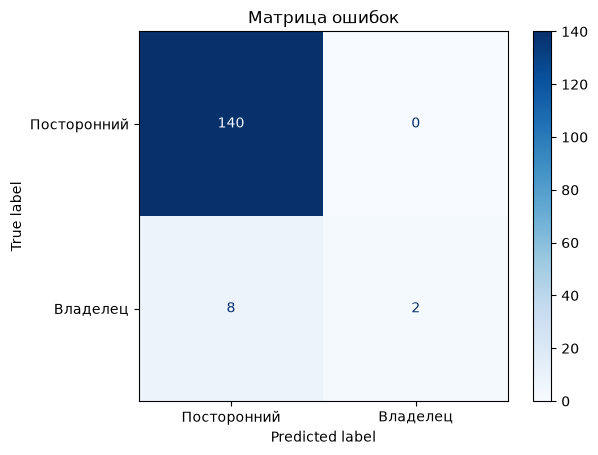

In [22]:
all_valid_test_features = []
for i in range(len(user_folders)):
    all_valid_test_features.append(get_user_features(user_folders, "valid", num_user=i, filt=1))

X_owner = all_valid_test_features[0]

impostor_matrices = []
for user_index in range(len(user_folders)):
    if user_index == 0:
        continue
    impostor_matrices.append(all_valid_test_features[user_index])
X_impostors = np.vstack(impostor_matrices)

X_validation = np.vstack([
    X_owner,
    X_impostors
])

y_validation = np.concatenate([
    np.ones(len(X_owner), dtype=int),
    np.zeros(len(X_impostors), dtype=int)
])


X_validation_scaled = scaler.transform(X_validation)
svm_predictions = model.predict(X_validation_scaled)
y_pred = (svm_predictions == 1).astype(int)

cm = confusion_matrix(y_validation, y_pred, labels=[0, 1])
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Посторонний", "Владелец"])

cm_display.plot(cmap="Blues")
plt.title("Матрица ошибок")
plt.show()

# Финальный расчет

П Р И М Е Р:
Загрузка данных в память...
Метрики всех пользователей:


,user,ROC_AUC,ROC_pairs,PR_AUC,FAR,FRR,EER,threshold,TN,FP,FN,TP
0,0,1.0000,14,1.0000,0.0000,0.0,0.0000,-0.1808,140,0,0,10
1,1,0.9900,14,0.9123,0.0500,0.0,0.0250,-0.2990,133,7,0,10
2,2,0.9986,14,0.9799,0.0071,0.0,0.0036,-0.2150,139,1,0,10
3,3,0.9150,14,0.6587,0.1786,0.2,0.1893,-0.3236,115,25,2,8
4,4,1.0000,14,1.0000,0.0000,0.0,0.0000,-0.2002,140,0,0,10
5,5,1.0000,14,1.0000,0.0000,0.0,0.0000,-0.4075,140,0,0,10
6,6,1.0000,14,1.0000,0.0000,0.0,0.0000,-0.1301,140,0,0,10
7,7,1.0000,14,1.0000,0.0000,0.0,0.0000,-0.3987,140,0,0,10
8,8,0.9743,14,0.7546,0.0714,0.0,0.0357,-0.4293,130,10,0,10
9,9,1.0000,14,1.0000,0.0000,0.0,0.0000,-0.3224,140,0,0,10



Сводные показатели:


,mean,std,median,min,max
ROC_AUC,0.9903,0.0219,0.9986,0.9150,1.0000
PR_AUC,0.9394,0.1007,0.9799,0.6587,1.0000
FAR,0.0324,0.0506,0.0071,0.0000,0.1786
FRR,0.0267,0.0594,0.0000,0.0000,0.2000
EER,0.0295,0.0533,0.0036,0.0000,0.1893


Количество попарных ROC AUC: 210


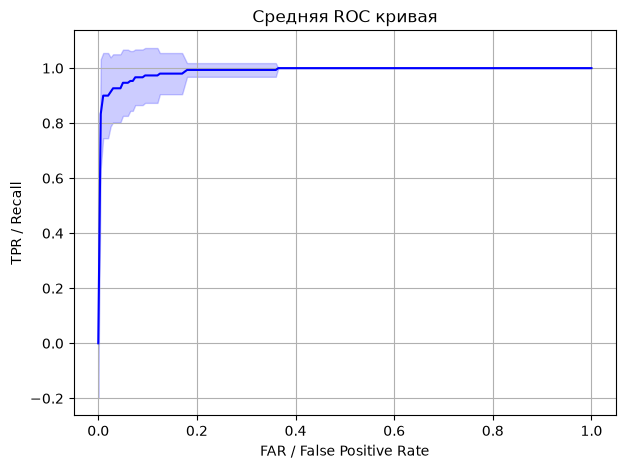

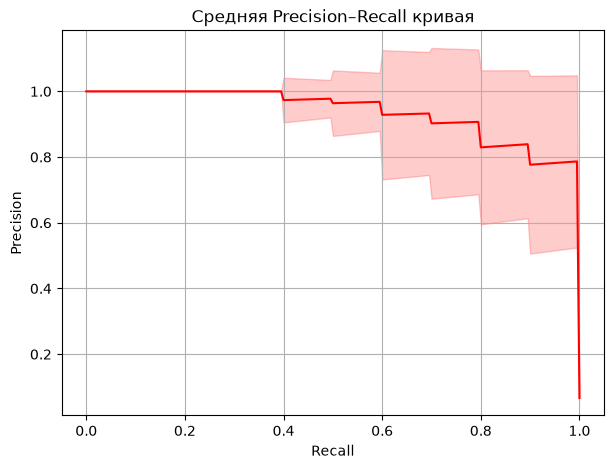

In [26]:
def get_all_valid_test_features(user_folders, valid_test, filt):
    print("Загрузка данных в память...")
    all_valid_test_features = []
    for i in range(len(user_folders)):
        all_valid_test_features.append(get_user_features(user_folders, valid_test, num_user=i, filt=filt))
    return all_valid_test_features


def evaluate_one_user(user_folders, all_valid_test_features, owner_user,
                      mean_fpr_grid, mean_recall_grid, filt, model_id, eer_threshold=None):

    X_train = get_user_features(user_folders, "train", num_user=owner_user, filt=filt)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    
    if model_id == 1:
        model = OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=0.1
        )

    if model_id == 2:
        model = IsolationForest(
            n_estimators=200,
            contamination=0.1,
            random_state=1
        )
    model.fit(X_train_scaled)

    X_owner = all_valid_test_features[owner_user]

    impostor_matrices = []
    pair_roc_auc_values = []
    for user_index in range(len(user_folders)):
        if user_index == owner_user:
            continue
    
        X_impostor = all_valid_test_features[user_index]
        impostor_matrices.append(X_impostor)
    
        X_pair = np.vstack([
            X_owner,
            X_impostor
        ])
    
        y_pair = np.concatenate([
            np.ones(len(X_owner), dtype=int),
            np.zeros(len(X_impostor), dtype=int)
        ])
    
        X_pair_scaled = scaler.transform(X_pair)
        pair_scores = model.decision_function(X_pair_scaled)
        pair_roc_auc = roc_auc_score(y_pair, pair_scores)
        pair_roc_auc_values.append(pair_roc_auc)
    
    
    roc_auc = np.mean(pair_roc_auc_values)
    
    X_impostors = np.vstack(impostor_matrices)
    
    X_valid_test = np.vstack([
        X_owner,
        X_impostors
    ])
    
    y_valid_test = np.concatenate([
        np.ones(len(X_owner), dtype=int),
        np.zeros(len(X_impostors), dtype=int)
    ])
    
    X_scaled = scaler.transform(X_valid_test)
    scores = model.decision_function(X_scaled)

    fpr, tpr, roc_thresholds = roc_curve(y_valid_test, scores)
    far_values = fpr
    frr_values = 1 - tpr

    if eer_threshold is None:
        eer_index = np.argmin(np.abs(far_values - frr_values))
        eer_threshold = roc_thresholds[eer_index]
        eer = (far_values[eer_index] + frr_values[eer_index]) / 2
    else:
        eer = np.nan

    y_pred = (scores >= eer_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_valid_test, y_pred, labels=[0, 1]).ravel()

    far = fp / (fp + tn)
    frr = fn / (fn + tp)

    precision, recall, pr_thresholds = precision_recall_curve(y_valid_test, scores)
    pr_auc = auc(recall[::-1], precision[::-1])
    
    metrics = {
        "user": owner_user,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
        "FAR": far,
        "FRR": frr,
        "EER": eer,
        "threshold": eer_threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

    interpolated_tpr = np.interp(mean_fpr_grid, fpr, tpr)
    interpolated_precision = np.interp(mean_recall_grid, recall[::-1], precision[::-1])
    curve_data = {"tpr": interpolated_tpr, "precision": interpolated_precision}

    return metrics, curve_data


def show_metrics_summary(metrics_table):

    print("Метрики всех пользователей:")
    display(metrics_table.round(4))

    metric_names = ["ROC_AUC", "PR_AUC", "FAR", "FRR", "EER"]
    summary_table = metrics_table[metric_names].agg(["mean", "std", "median", "min", "max"]).T

    print("\nСводные показатели:")
    display(summary_table.round(4))

    return


def plot_mean_curves(curve_data_list, metrics_table, mean_fpr_grid, mean_recall_grid):

    tpr_array = np.array([curve_data["tpr"] for curve_data in curve_data_list])
    mean_tpr = np.mean(tpr_array, axis=0)
    std_tpr = np.std(tpr_array, axis=0)
    mean_tpr[0] = 0
    mean_tpr[-1] = 1

    precision_array = np.array([curve_data["precision"] for curve_data in curve_data_list])
    mean_precision = np.mean(precision_array, axis=0)
    std_precision = np.std(precision_array, axis=0)

    plt.figure(figsize=(7, 5))

    plt.plot(mean_fpr_grid, mean_tpr, color="blue")
    plt.fill_between(mean_fpr_grid, mean_tpr - std_tpr, mean_tpr + std_tpr, color="blue", alpha=0.2)
    plt.xlabel("FAR / False Positive Rate")
    plt.ylabel("TPR / Recall")
    plt.title("Средняя ROC кривая")
    plt.grid(True)

    plt.show()

    plt.figure(figsize=(7, 5))

    plt.plot(mean_recall_grid, mean_precision, color="red")
    plt.fill_between(mean_recall_grid, mean_precision - std_precision, mean_precision + std_precision, color="red", alpha=0.2)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Средняя Precision–Recall кривая")
    plt.grid(True)

    plt.show()


def run_all_users_analysis(user_folders, valid_test, filt, model_id, eer_thresholds=None):

    mean_fpr_grid = np.linspace(0, 1, 201)
    mean_recall_grid = np.linspace(0, 1, 201)

    all_valid_test_features = get_all_valid_test_features(user_folders, valid_test, filt)

    metrics_rows = []
    curve_data_list = []

    for owner_user in range(len(user_folders)):
        eer_threshold = None
        
        if eer_thresholds is not None:
            eer_threshold = eer_thresholds[owner_user]

        metrics, curve_data = evaluate_one_user(
            user_folders=user_folders,
            all_valid_test_features=all_valid_test_features,
            owner_user=owner_user,
            mean_fpr_grid=mean_fpr_grid,
            mean_recall_grid=mean_recall_grid,
            filt=filt,
            model_id=model_id,
            eer_threshold=eer_threshold
        )

        metrics_rows.append(metrics)
        curve_data_list.append(curve_data)

    metrics_table = pd.DataFrame(metrics_rows)
    show_metrics_summary(metrics_table)

    plot_mean_curves(
        curve_data_list=curve_data_list,
        metrics_table=metrics_table,
        mean_fpr_grid=mean_fpr_grid,
        mean_recall_grid=mean_recall_grid
    )

    return metrics_table

print("П Р И М Е Р:")
validation_metrics = run_all_users_analysis(user_folders, "valid", filt=1, model_id=1)
validation_thresholds = validation_metrics["threshold"].to_numpy()

#run_all_users_analysis(user_folders, "valid", filt=1, model_id=1)
#run_all_users_analysis(user_folders, "valid", filt=2, model_id=1)
#run_all_users_analysis(user_folders, "valid", filt=0, model_id=2)
#run_all_users_analysis(user_folders, "valid", filt=1, model_id=2)
#run_all_users_analysis(user_folders, "valid", filt=2, model_id=2)

# Исследование результатов различных комбинаций

ДО НОВЫХ СТАТИСТИК:  
**без фильтра + МОВ :**  
mean ROC AUC = 0.9894  
mean PR AUC = 0.9196  

**Баттерворт + МОВ :**   
mean ROC AUC = 0.9890  
mean PR AUC = 0.9218   

**медианный + МОВ :**   
mean ROC AUC = 0.9885  
mean PR AUC = 0.9174  

**без фильтра + лес :**   
mean ROC AUC = 0.9700  
mean PR AUC = 0.8591   

**Баттерворт + лес :**  
mean ROC AUC = 0.9694  
mean PR AUC = 0.8613  

**медианный + лес :**   
mean ROC AUC = 0.9681  
mean PR AUC = 0.8578  

===========  


ПОСЛЕ НОВЫХ СТАТИСТИК:  
**без фильтра + МОВ :**    
mean ROC AUC = 0.9902  
mean PR AUC = 0.9401  

**Баттерворт + МОВ :**   
mean ROC AUC = 0.9903  
mean PR AUC = 0.9394  

**медианный + МОВ :**   
mean ROC AUC = 0.9887  
mean PR AUC = 0.9353   

**без фильтра + лес :**   
mean ROC AUC = 0.9773  
mean PR AUC = 0.8756  

**Баттерворт + лес :**   
mean ROC AUC = 0.9756  
mean PR AUC = 0.8658  
 
**медианный + лес :**  
mean ROC AUC = 0.9744  
mean PR AUC = 0.8683  

===========

КОМБИНАЦИЯ ФИЛЬРОВ:  
**медианный + Баттерворт + МОВ :**  
mean ROC AUC = 0.9861   
mean PR AUC = 0.9344  

===========  

ПОСЛЕ СОКРАЩЕНИЯ ПРОСТРАНСТВА:  
все показатели стали немного хуже (меньше чем на 0.01, но всё таки хуже)

# ИТОГО 
Для тестовых данных была выбрана комбинация фильтр Баттерворта + oneclass SVM, т.к. именно эта комбинация показала наилучшие результаты для валидационных данных

Загрузка данных в память...
Метрики всех пользователей:


,user,ROC_AUC,PR_AUC,FAR,FRR,EER,threshold,TN,FP,FN,TP
0,0,0.9988,0.9826,0.0000,0.1000,NaN,-0.1798,160,0,1,9
1,1,0.9857,0.9281,0.0566,0.0909,NaN,-0.2998,150,9,1,10
2,2,0.9881,0.8890,0.0188,0.2000,NaN,-0.2232,157,3,2,8
3,3,0.9412,0.4778,0.2000,0.0000,NaN,-0.3317,128,32,0,10
4,4,1.0000,1.0000,0.0000,0.3077,NaN,-0.2196,157,0,4,9
5,5,1.0000,1.0000,1.0000,0.0000,NaN,-0.4515,0,160,0,10
6,6,1.0000,1.0000,0.0000,0.3333,NaN,-0.1646,161,0,3,6
7,7,0.9992,0.9936,0.0000,0.1765,NaN,-0.4288,153,0,3,14
8,8,0.9950,0.9246,0.0812,0.0000,NaN,-0.4300,147,13,0,10
9,9,1.0000,1.0000,0.0000,0.2222,NaN,-0.3233,152,0,4,14



Сводные показатели:


,mean,std,median,min,max
ROC_AUC,0.9925,0.0150,0.9988,0.9412,1.0000
PR_AUC,0.9313,0.1320,0.9826,0.4778,1.0000
FAR,0.1021,0.2541,0.0188,0.0000,1.0000
FRR,0.1081,0.1157,0.0909,0.0000,0.3333
EER,NaN,NaN,NaN,NaN,NaN


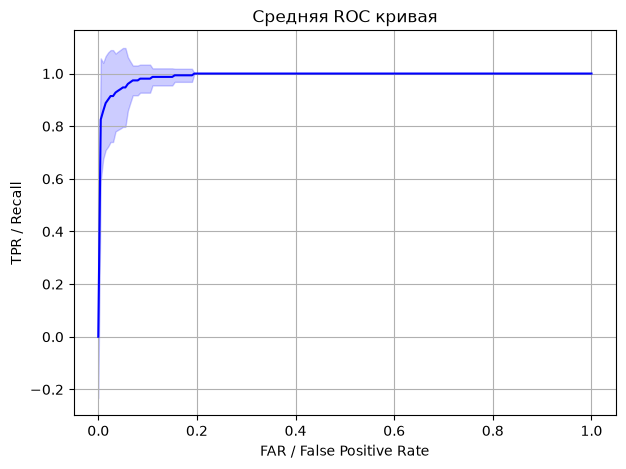

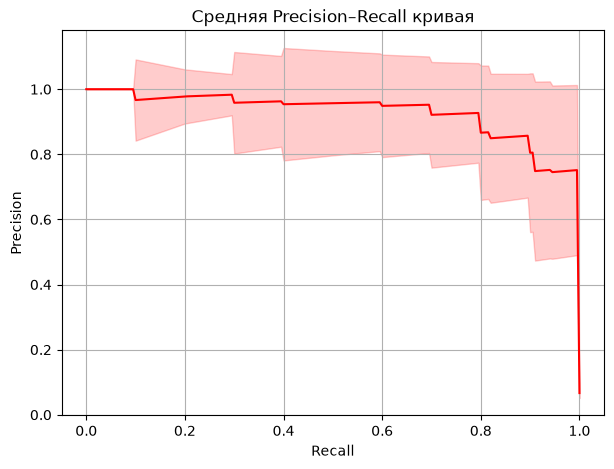

In [24]:
test_metrics = run_all_users_analysis(user_folders, "test", filt=1, model_id=1, eer_thresholds=validation_thresholds)